# 

# Машинное обучение. ВМК МГУ

# Практическое задание 2. Knn: классификация и регрессия

## Уровень: <font color='MediumSeaGreen'>**Исследовательский (Research)**</font>

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличе работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

-----------
<font color="white" style="opacity:0.2024"></font>







<font color=DarkOrange>**Примерное время выполнения (execution time/время выполнения, если нажать run all) всех ячеек ноутбука при правильной реализации: 10 минут </font>**

# Подготовка рабочей среды

Сначала установим нужные нам версии библиотек. Мы гарантируем, что в данных версиях задание будет корректно отрабатывать.

После установки нужных версий, **возможно,** нужно перезагрузить среду (runtime), но скорее всего вам это не понадобится


На скачивание файла и установку понадобится не более 5 минут.

<font color='OrangeRed'>**Важно!**</font>

Устанавливать нужные версии нужно каждый раз, когда создается новый рантайм. Например, если вы 2 часа подряд делаете это задание, то подготовить библиотеки достаточно 1 раз. Но если вы, например, начали в понедельник, затем закрыли/выключили ноутбук, то при продолжении в среду, вам нужно будет запустить рантайм заново и следовательно заново установить библиотеки.

<font color='OrangeRed'>**Важно!**</font>
Если вы предпочитаете делать практические задания на своем личном ноутбуке, то проверьте, что вы установили рабочее окружение в [соответствии с гайдом](https://github.com/MSU-ML-COURSE/ML-COURSE-24-25/blob/main/tutorials/%D0%A2%D1%83%D1%82%D0%BE%D1%80%D0%B8%D0%B0%D0%BB%20%D0%BF%D0%BE%20%D1%83%D1%81%D1%82%D0%B0%D0%BD%D0%BE%D0%B2%D0%BA%D0%B5%20%D1%80%D0%B0%D0%B1%D0%BE%D1%87%D0%B5%D0%B3%D0%BE%20%D0%BE%D0%BA%D1%80%D1%83%D0%B6%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B2%20Python%20%D0%B4%D0%BB%D1%8F%20%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%20(2).pdf)

In [ ]:
# Установка зависимостей выполняется отдельно по requirements.txt.
# Установка зависимостей выполняется отдельно по requirements.txt.


Проверим версию библиотеки:

In [ ]:
import catboost
assert(catboost.__version__ == '1.2.8')


<font color='OrangeRed'>**Внимание!**</font> Перед выполнение данного задания рекомендуем сначала погрузиться в [Base] ноутбук по основам sklearn, нормализации и кросс-валидации, так как данные техники и понятия будут активно использоваться в данном ноутбук

Теперь можно приступать к выполнению задания! :)

-----------
<font color="white" style="opacity:0.2024"></font>

# Часть 1. Нормализация признакового пространства

В данном части задания исследуем, как нормализация (скейлинг) данных влияет на разделимость данных

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
import numpy as np
import seaborn as sns
import pickle

from matplotlib import pyplot as plt


plt.rcParams["figure.figsize"] = (5,5)

Загрузим файл с данными data.pkl:

In [ ]:
!gdown 1acbP4PNmu11rkBzozvIc3bowWaQL7iFe

Загрузим данные в память. В переменной $X$ будут храниться признаковые описания объектов, в переменной $y~-$ метки классов

In [ ]:
with open('data/data.pkl', 'rb') as file:
    X, y = pickle.load(file)

In [ ]:
def plot_data_points(X, labels, xlim, ylim):
    g = sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=labels)
    g.set(xlim=xlim, ylim=ylim)
    plt.xlabel('x_1')
    plt.ylabel('x_2')
    plt.grid()

Визуализируем наши данные

In [ ]:
plot_data_points(X, y, xlim=(-15, 15), ylim=(-15, 15))

Как видно, наши данные идеально разделяются прямой $x=0$

Функция $plot\_knn\_bound$ принимает на вход объекты $X$, метки классов $y$, метод нормализации признаков $scaler$, число соседей $n\_neighbors$ и границы рисунка $xlim$, $ylim$. Функция обучает $KNN$ классификатор с числом соседей $n\_neighbors$ и визуализирует разделяющую поверхность для классов, полученную с помощью обученного $KNN$ классификатора.

* Если вы не можете различить _выбранные нами цвета_, то измените список цветов в переменных cmap_light и cmap_bold. Актуальный список возможных цветов находится [здесь](https://matplotlib.org/stable/tutorials/colors/colormaps.html)

In [ ]:
from matplotlib.colors import ListedColormap
from sklearn import neighbors, datasets

def plot_knn_bound(X, y, scaler=None, n_neighbors=10, xlim=(-15, 15), ylim=(-20, 20)):
    # step size in the mesh
    h = 0.05

    # Create color maps
    cmap_light = ListedColormap(['C0', 'orange', 'cyan', 'green'][:np.unique(y).shape[0]])
    cmap_bold = ['C0', 'orange', 'c', 'darkgreen'][:np.unique(y).shape[0]]

    x_min, x_max = xlim
    y_min, y_max = ylim
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]

    X_scaled = X # if scaler is None
    if scaler is not None:
        grid = scaler.transform(grid)
        X_scaled = scaler.transform(X)

    # we create an instance of Neighbours Classifier and fit the data.
    clf = neighbors.KNeighborsClassifier(n_neighbors, algorithm='brute')
    clf.fit(X_scaled, y)

    Z = clf.predict(grid)

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=cmap_light)

    # Plot also the training points
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y,
                    palette=cmap_bold, alpha=1.0, edgecolor="black")
    plt.xlabel('x_1')
    plt.ylabel('x_2')
    plt.title('Разделющие поверхности алгоритма {}-NN'.format(n_neighbors))
    plt.grid()
    plt.show()

Нарисуем разделющие поверхности $1$-$NN$ и $10$-$NN$

In [ ]:
plot_knn_bound(X, y, n_neighbors=1)
plot_knn_bound(X, y, n_neighbors=10)

## <font color='DarkOrange'>**Задание 1.1 (кросс-проверка, 1,5 балла)**</font>

 Объясните, почему наблюдается сильное отклоенние разделяющей поверхности от прямой $x_1=0$ при значениях $x_2 < -10$ и $x_2 > 10$. Дайте <font color='OrangeRed'>**строгое математическое обоснование**</font> наблюдаемого явления, показывающее, что в Евклидовом пространстве данная проблема решается нормализацией (скейлингом) признаков.

<font color='MediumOrchid'>**Ваше обоснование тут, можно использовать LaTeX: Пусть для ясности x_2 есть ось y, x_1 есть ось x.
KNN использует евклидово расстояние:

$d(P1​,P2​)=\sqrt{(x_1​−x_2​)^2+(y_1​−y_2​)^2}$
​

В области $|y|>10$ и x, близким к 0, ближайшие соседи точки (x,y) — это точки обучающей выборки с наибольшими по модулю y (близкими к y=10 или y= -10), потому что разница по y доминирует над разницей по x при подсчете расстояний.

Рассмотрим точку (2,-100)
Видим на графике, что ближайшие точки обучающей выборки с положительным x имеют значение y≈-10 и x≈2,
тогда как есть точки с x<0, имеющие y≈-12, x≈-2.
При подсчете расстояний имеем:

$\sqrt{(2-2)^2+ (-10-100)^2}$ = 90

$\sqrt{(-2-2)^2+ (-12-100)^2}$ = $\sqrt{7760} < \sqrt{8100} = 90$

То есть для точки находящейся на положительной по x полуплоскости ближе точки обучающей выборки из отрицательной полуплоскости, чей класс и присваивается рассматриваемой точке. Поэтому разделяющая поверхность отклоняется в сторону при y<-10. Аналогично с y>10.

Нормализация (скейлинг) приводит признаки к одинаковому масштабу. После этого евклидово расстояние становится масштабно-инвариантным в пространстве признаков и оба признака (разница по оси x и по оси y) вносят равный вклад в расстояние.
**</font>

---

## <font color='DarkOrange'>**Задание 1.2 (кросс-проверка, 2 балла)**</font>


 Пусть дано произвольное число точек на плоскости. Представим, что каждая точка - это отдельный класс. Пусть на данной выборке был обучен $1-NN$ классификатор. Чем с геометрической точки зрения являются разделяющие поверхности этого классификатора? Требуется <font color='OrangeRed'>**математически строго, однозначно и с полным обоснованием**</font> определить геометрическое место точек разделяющих поверхностей.

В качестве примера ниже представлена визуализация для четырех точек

In [ ]:
X = np.random.randn(4, 2)
y = np.arange(4)
plot_knn_bound(X, y, n_neighbors=1, xlim=(-3, 3), ylim=(-3, 3))

<font color='MediumOrchid'>**Ваше обоснование тут, можно использовать LaTeX:
 Разделяющие поверхности 1-NN классификатора на плоскости — это сегменты срединных перпендикуляров к отрезкам, соединяющим пары точек разных классов, ограниченные диаграммой Вороного множества всех точек обучающей выборки.
Обоснование:

набор точек на плоскости S={$P_1,P_2,…,P_n$}, для каждой точки свой класс.

Пусть Q - произвольная точка на плоскости.

Геометрическое место точек, для которых существуют по крайней мере два ближайших соседа из исходного множества точек из разных классов — это и есть разделяющая поверхность.

диаграмма Вороного — это разбиение плоскости на n ячеек $Vi$ вида

$V_i$​={$Q∈R_2∣d(Q,P_i​)≤d(Q,P_j​), ∀j \neq i$}. $d$ - метрика.

$Bisector()$ - срединный перпендикуляр к отрезку $[P_i,P_j]$, что есть геометрическое место точек, равноудаленнных от двух заданных точек. В нашем случае выходит, что у точек на таких перпендикулярах может быть два ближайших соседа, что как раз присуще разделяющей поверхности. Берутся перпендикуляры сегментами, а не целиком, потому что при отдалении точки пересечения отрезка $[P_i,P_j]$ и перпендикуляра может найтись 3я точка сосед, что будет ближе, чем $P_i$ и $P_j$. Поэтому перпендикуляры нужно ограничить множествами $V_i$.

Итого разделяющая поверхность =

= $\bigcup_{P_i​,P_j​∈S; class(P_i​) \neq class(P_j​)}​(Bisector(P_i​,P_j)​\cap \overline{V_i}​​\cap \overline{V_j​​})$,



**</font>

# Часть 2. Кросс-валидация

Чтобы закрепить понимание устройства кросс-валидации предлагаем вам запрограммировать данный метод самостоятельно

## <font color='DarkOrange'>**Задание 2.1 (unit-tests, 3 балла)**</font>

 В модуле `cross_val.py` реализуйте функции

* $kfold\_split$, которая реализует генерацию индексов обучающей и валидационной выборок для кросс-валидации
* $knn\_cv\_score$, которая реализует кросс-валидацию для $KNN-$модели
   
Примеры запусков функций можно увидеть в открытых тестах.

----

# Часть 3. Работа с текстовыми данными

Далее будем решать задачу классификации новостного текста к одному из 20 классов, каждый класс соответствует определенной новостной тематике.

- В качестве метрики качества будем использовать $accuracy\_score$.

<font color='CornflowerBlue'>**Accuracy**</font> - это доля верно классифицированных объектов, среди всех объектов выборки.

In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [ ]:
X_train, y_train = fetch_20newsgroups(subset='train', return_X_y=True, random_state=42)
X_test, y_test = fetch_20newsgroups(subset='test', return_X_y=True, random_state=42)

In [ ]:
print(X_train[0])

In [ ]:
X_train = np.array(X_train, dtype=object)

In [ ]:
X_test = np.array(X_test, dtype=object)

In [ ]:
y_train = np.array(y_train)
y_test = np.array(y_test)

Как мы видим, объектами обучающей выборки являются тексты. Сырые текстовые данные не могут служить обучающими примерами для алгоритма $KNN$. Перед использованием $KNN$ текстовые данные переменной длины необходимо отобразить в числовой вектор фиксированной размерности.

Работа с текстовыми данными проходит в несколько этапов.

* <font color='plum'>**Токенизация.**</font> Текстовая строка делится на токены. Как правило, в качестве токенов выступают отдельные слова и знаки препинания.

* <font color='plum'>**Нормализация.**</font> Приведение к нижнему регистру, удаление стоп-слов, удаление пунктуации, удаление редких и частотных слов и т.д.

* <font color='plum'>**Векторизация.**</font> Фиксируется словарь токенов $V$ по **обучающей** выборке. Текст представлется в виде вектора длиной $|V|$, где каждый признак есть функция от частоты встречаемости токена в тексте и в обучающей выборке.

В данном задании будет использовано два вида векторизации.

* Первый, $CountVectorizer$, сопоставляет каждому токену частоту встречаемости этого токена в тексте документа.

*  Второй, $TfidfVectorizer$, сопоставляет каждому токену частоту встречаемости этого токена в тексте документа умноженную на величину обратно пропорциональную частоте встречаемости токена во всех документах **обучающей** выборки. Подробне про $tf-idf$ предлагаем изучить самостоятельно, например, [здесь](https://ru.wikipedia.org/wiki/TF-IDF).

<font color='MediumTurquoise'>**Полезные ссылки**</font>

Более подробно про работу с текстами можно прочитать в [статье](https://habr.com/ru/companies/otus/articles/687796/) на Хабре и в [NLTK Book](https://www.nltk.org/book/).

В `sklearn` все векторизаторы автоматически токенизируют текст и приводят его к нижнему регистру. Параметры $max\_df$ и $min\_df$ позволяют убрать из словаря наиболее частые и наиболее редкие токены. Параметр $stop\_words$ позволяет убрать из словаря стоп-слова (малоинформативные слова для данного языка, например, союзы).

In [ ]:
count_vec = CountVectorizer(max_df=0.8, min_df=10, max_features=1000, stop_words='english')
tf_idf = TfidfVectorizer(max_df=0.8, min_df=10, max_features=1000, stop_words='english')

## <font color='DarkOrange'>**Задание 3.1 (кросс-проверка, 0,5 баллa)**</font>

 Найдите оптимальные параметры обучения модели. Осуществлять перебор параметров следует по заданной ниже сетке.

 - Используйте реализованные вами функции $kfold\_split$, $knn\_cv\_score$. В качестве метрики используйте $accuracy\_score$. 3х фолдов для кросс-валидации будет достаточно.

In [ ]:
from sklearn.metrics import accuracy_score

parameters = {
    'n_neighbors': [i for i in range(1, 11)],
    'metrics': ['cosine'],
    'weights': ['uniform', 'distance'],
    'normalizers': [(count_vec, 'CountVectorizer'), (tf_idf, 'TfidfVectorizer')]
}


Если вы все сделаете правильно, то запущенная вами кросс-валидация будет работать примерно 7 минут. Дождитесь ее завершения, не закрывайте и не перезагружайте этот colab ноутбук.

In [ ]:
from sklearn import neighbors
from cross_val import kfold_split, knn_cv_score
folds = kfold_split(len(X_train), 3)

out = knn_cv_score(X_train, y_train, parameters, accuracy_score, folds, neighbors.KNeighborsClassifier)
out

## <font color='DarkOrange'>**Задание 3.2 (кросс-проверка, 0,5 балл)**</font>

 Какой метод предобработки данных в среднем дает наилучший результат? Почему?

In [ ]:
best_score = max(out.values())
best_params = [k for k, v in out.items() if v == best_score]
print("best score = ", best_score)
print("best params = ", best_params)
scores_1 = np.array([out[key] for key in out if key[0] == 'CountVectorizer'])
scores_2 = np.array([out[key] for key in out if key[0] == 'TfidfVectorizer'])
count_mean_score = np.mean(scores_1)
tfid_mean_score = np.mean(scores_2)
print("CountVectorizer mean score = ", count_mean_score)
print("TfidfVectorizer mean score = ", tfid_mean_score)



<font color='MediumOrchid'>**Ваш ответ тут: В среднем результат лучше с TfidfVectorizer. Иногда проблемой CountVectorizer может стать момент, когда в тексте некоторые слова присутствуют очень часто, но при этом не несут никакой значимой информации о фактическом содержании текста (документа). Если такие данные передавать непосредственно классификатору, то такие частые термины могут затенять частоты более редких, но при этом более интересных терминов. TfidfVectorizer отчасти решает данную проблему своей реализацией, где редкие, но важные слова тоже имеют вес. Это может быть причиной более хорошего результата.**</font>

## <font color='DarkOrange'>**Задание 3.3 (кросс-проверка, 1 балл)**</font>

 Начертите график (line plot) зависимости метрики качества от числа соседей. Метрику следует усреднить по всем параметрам, кроме числа соседей. Сделайте выводы о наблюдаемых зависимостях (возможно будет полезным ознакомиться с названиями классов)

In [ ]:
import matplotlib.pyplot as plt
n_count = parameters['n_neighbors']
n_scores = []
plt.figure(figsize=(10,5))
for n in n_count:
  scores = np.array([out[key] for key in out if key[1] == n])
  n_scores.append(np.mean(scores))
plt.plot(n_count, n_scores, color='red', marker='.')
plt.grid()
plt.title("Зависимость метрики качества от числа соседей")
plt.xlabel("Число соседей")
plt.ylabel("Значение метрики")
plt.xlim(left=0, right=11)
plt.xticks(n_count)
plt.show()


<font color='MediumOrchid'>**Ваш ответ тут: Значение метрики уменьшается с ростом числа соседей. Причем разница в значениях между 1 соседом и 2 самая большая, далее зависимость монотонно убывающая, но уже не такая стремительная  **</font>

## <font color='DarkOrange'>**Задание 3.4 (кросс-проверка, 1,5 баллa)**</font>

 Оцените точность вашей лучшей модели на тестовой части датасета. Отличается ли оно от качества, полученного на кросс-валидации? Почему? При ответе на поставленные вопросы вам поможет анализ распределений обучающей и тестовой выборок

In [ ]:
p = best_params[1]
p

In [ ]:
tf_idf.fit(X_train)
X_train_new = tf_idf.transform(X_train)
X_test_new = tf_idf.transform(X_test)
model = neighbors.KNeighborsClassifier(metric = p[2], n_neighbors=p[1], weights=p[3])
model.fit(X_train_new, y_train)
score = accuracy_score(y_test, model.predict(X_test_new))
print("точность лучшей модели на тестовой части датасета = ", score)
print("точность лучшей модели на кросс-валидации = ", best_score)

In [ ]:
classes = np.unique(y_test)
counts = np.array([np.sum(y_test== x) for x in classes])
colors = plt.cm.tab20(np.linspace(0, 1, 20))
plt.figure(figsize=(10,5))
for i in range(len(classes)):
  plt.bar(classes[i], counts[i], color=colors[i], label=classes[i])
plt.title("Распределение классов в тестовой выборке")
plt.xlabel("Классы")
plt.ylabel("Количество элементов класса")
plt.xticks([])
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.grid(axis='y', linewidth=0.4)
plt.show()

In [ ]:
classes = np.unique(y_train)
counts = np.array([np.sum(y_train== x) for x in classes])
colors = plt.cm.tab20(np.linspace(0, 1, 20))
plt.figure(figsize=(10,5))
for i in range(len(classes)):
  plt.bar(classes[i], counts[i], color=colors[i], label=classes[i])
plt.title("Распределение классов в тренировочной выборке")
plt.xlabel("Классы")
plt.ylabel("Количество элементов класса")
plt.xticks([])
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.grid(axis='y', linewidth=0.4)
plt.show()

In [ ]:
classes = np.unique(y_train)

folds = kfold_split(len(y_train), 3)
for j in range(3):
  y_new = y_train[folds[j][1]]
  counts = np.array([np.sum(y_new== x) for x in classes])
  colors = plt.cm.tab20(np.linspace(0, 1, 20))
  plt.figure(figsize=(10,5))
  for i in range(len(classes)):
    plt.bar(classes[i], counts[i], color=colors[i], label=classes[i])
  plt.title(f"Распределение классов в тренировочной выборке, {j+1} фолд")
  plt.xlabel("Классы")
  plt.ylabel("Количество элементов класса")
  plt.xticks([])
  plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
  plt.grid(axis='y', linewidth=0.4)
  plt.show()

<font color='MediumOrchid'>**Ваш ответ тут: Да, точность лучшей модели на тестовой части датасета отличается от полученной на кросс-валидации, причем она меньше. Причина в самой кросс-валидации. Изначально test и train части имеют одинаковые распределения, но во время кросс-валидации мы делим train часть. В полученных таким образом частях, судя по графикам, распределение немного другое. С отличным от тестовой выборки распределением и высчитывалась точность на кросс-валидации. То есть разница распределений тестовой и валидационных выборок может быть причиной отличия двух итоговых точностей: точности на тестовой части, и лучшей средней точности на кросс-валидации.  **</font>

# <font color='MediumSeaGreen'>**Бонус [0,5 балла]**</font>

 Вставьте мем, описывающий ваше состоянии после решения данного ноутбука

Ваша картинка тут

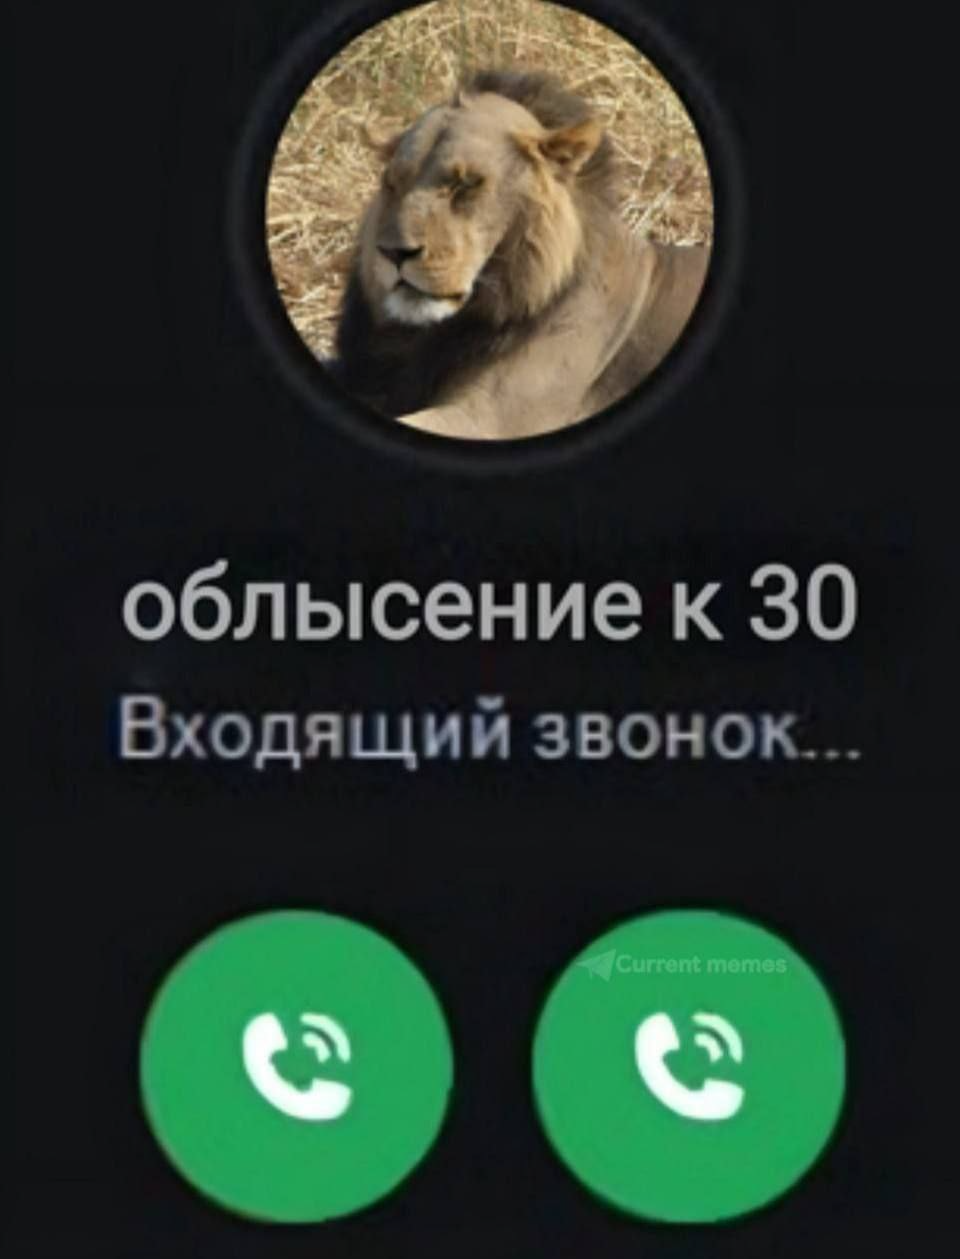